<h1 style="color: #00BFFF;">Amazon UK Product Insights</h1>

![legtsgo](https://i.giphy.com/media/v1.Y2lkPTc5MGI3NjExaWhwb2x2YjA1MjltMm1reTh3MDkzb2FsN21wenE3b2pjdnp4ems4dCZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/SvckSy7fFviqrq8ClF/giphy.gif)

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable insights.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
provides information on product categories, brands, prices, ratings, and more from from Amazon UK.

In [83]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
pd.options.display.float_format = "{:.2f}".format
np.set_printoptions(suppress=True)
from scipy.stats import chi2_contingency
from scipy import stats

In [9]:
df = pd.read_csv("amz_uk_price_prediction_dataset/amz_uk_price_prediction_dataset.csv")

In [10]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.70,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.70,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.70,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.60,1881,17.99,False,0,Hi-Fi Speakers


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [12]:
# Check for duplicates, NaNs and empty strings
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}  |  Duplicated rows: {df.duplicated().sum()}")

quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nulls": df.isna().sum(),
    "nulls_%": (df.isna().mean() * 100).round(1),
    "blanks": df.apply(lambda col: col.astype("string").str.strip().eq("").sum()),  # "", " ", "   "
    "n_unique": df.nunique(),
})

# Keep only the columns that actually have a problem, worst first
quality[(quality["nulls"] > 0) | (quality["blanks"] > 0)].sort_values("nulls_%", ascending=False)

Rows: 2443651  |  Columns: 9  |  Duplicated rows: 0


,dtype,nulls,nulls_%,blanks,n_unique


In [13]:
round(df.describe().T,2)

,count,mean,std,min,25%,50%,75%,max
uid,2443651.00,1370545.35,816056.17,1.00,658921.50,1349029.00,2060685.50,2828593.00
stars,2443651.00,2.15,2.19,0.00,0.00,0.00,4.40,5.00
reviews,2443651.00,480.63,5944.12,0.00,0.00,0.00,59.00,1356658.00
price,2443651.00,89.24,345.61,0.00,9.99,19.09,45.99,100000.00
boughtInLastMonth,2443651.00,25.90,240.48,0.00,0.00,0.00,0.00,50000.00


**Frequencies** 

Top 5 most listed product categories

In [14]:
Top_5=(df['category'].value_counts()).head(5).reset_index(name="count").merge((df['category'].value_counts(normalize=True).round(4)).head(5).reset_index(name="proportion"), on="category")
display(Top_5)

,category,count,proportion
0,Sports & Outdoors,836265,0.34
1,Beauty,19312,0.01
2,"Handmade Clothing, Shoes & Accessories",19229,0.01
3,Bath & Body,19092,0.01
4,Birthday Gifts,18978,0.01


Distribution of products across different categories

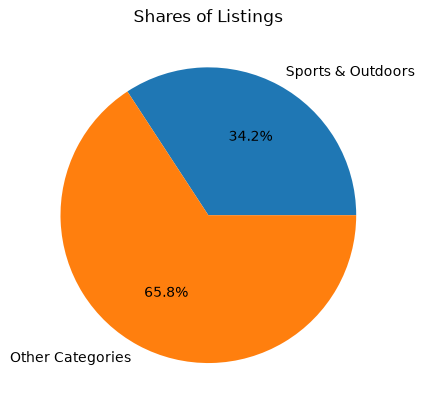

In [15]:
sports = (df["category"] == "Sports & Outdoors").sum()
other = (df["category"] != "Sports & Outdoors").sum()
plt.pie([sports,other],labels=["Sports & Outdoors", "Other Categories"],autopct="%1.1f%%") 
plt.title("Shares of Listings")
plt.show()

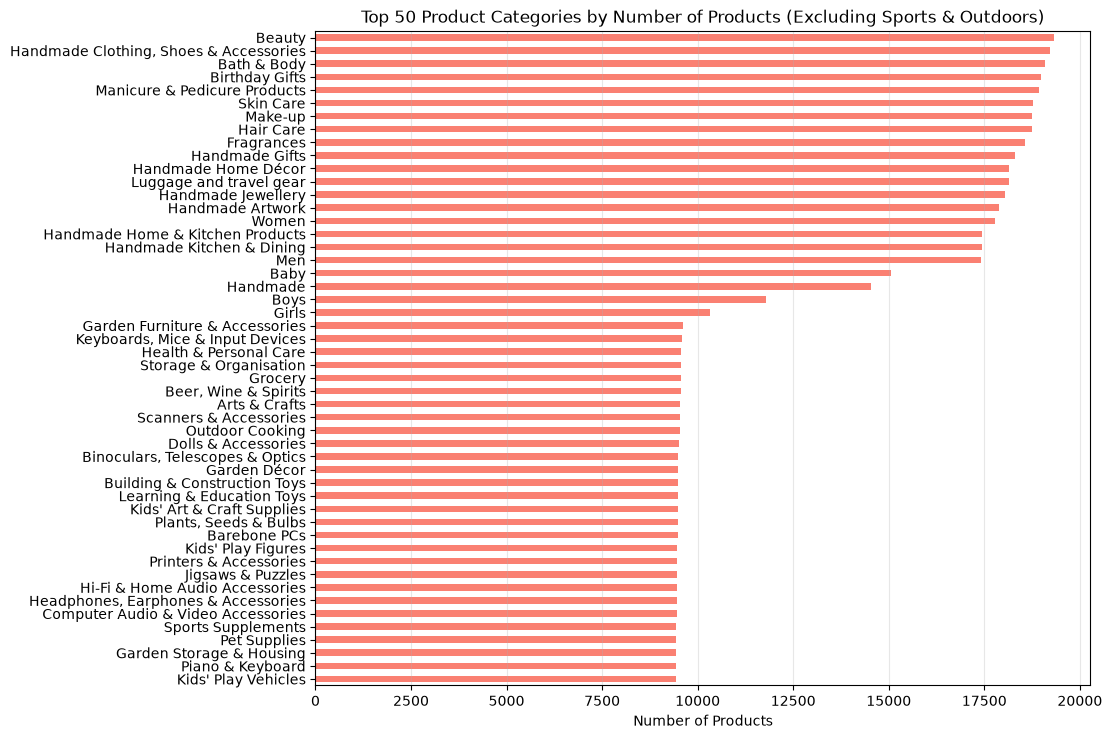

In [16]:
top_cat = df[df['category']!="Sports & Outdoors"]['category'].value_counts().head(50).sort_values()
ax = top_cat.plot(kind="barh",figsize=(10, 8.5),color="salmon", title="Top 50 Product Categories by Number of Products (Excluding Sports & Outdoors)")
ax.set_xlabel("Number of Products")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.3)
plt.show()

**Product Pricing**

In [17]:
df_price = df[df["price"] > 0]
price_summary = pd.DataFrame({
    "Min": [round(df_price["price"].min(),10)],
    "Max": [df_price["price"].max()],
    "Mean": [df_price["price"].mean()],
    "Median": [df_price["price"].median()],
    "Mode": [df_price["price"].mode()[0]],
    "Variance": [df_price["price"].var()],
    "STD": [df_price["price"].std()],
    "Range": [df_price["price"].max() - df_price["price"].min()],
    "Interquartile range (IQR)": [df_price["price"].quantile(0.75) - df_price["price"].quantile(0.25)]
}).round(2)
price_summary

,Min,Max,Mean,Median,Mode,Variance,STD,Range,Interquartile range (IQR)
0,0.01,100000.00,89.24,19.09,9.99,119446.40,345.61,99999.99,36.00


Number of Products by Price Range (Considering wide price range, logarithmically spaced bins were used, so that all products could be grouped into appropriate price ranges)

In [18]:
bins = np.logspace(np.log10(df_price["price"].min()),np.log10(df_price["price"].max()),15)
labels = []
ranges = pd.cut(df_price["price"],bins=bins, include_lowest=True, precision=2)
price_ranges = ranges.value_counts(sort=False)
price_ranges

price
(0.0, 0.032]               703
(0.032, 0.1]                48
(0.1, 0.32]                358
(0.32, 1.0]               2410
(1.0, 3.16]              45575
(3.16, 10.0]            584305
(10.0, 31.62]           987543
(31.62, 100.0]          495435
(100.0, 316.23]         194706
(316.23, 1000.0]         93434
(1000.0, 3162.28]        33399
(3162.28, 10000.0]        5548
(10000.0, 31622.78]        165
(31622.78, 100000.0]         2
Name: count, dtype: int64

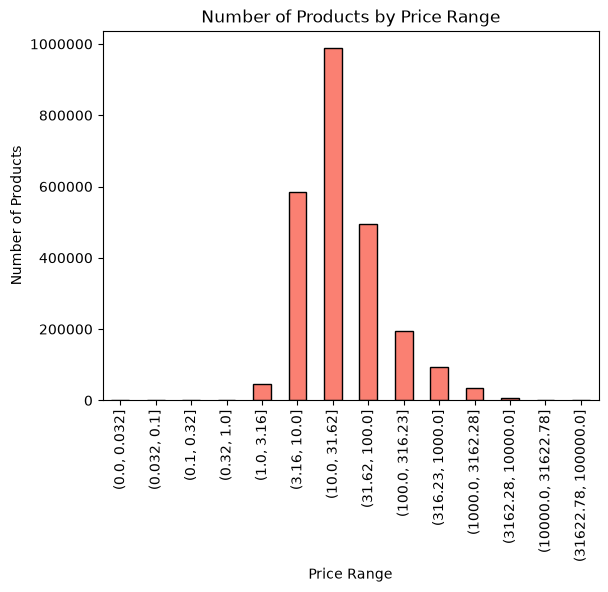

In [19]:
ax = price_ranges.plot(kind="bar",edgecolor="black",color="salmon")
ax.set_title("Number of Products by Price Range")
ax.set_ylabel("Number of Products")
ax.set_xlabel("Price Range")
plt.ticklabel_format(style="plain", axis="y")
plt.show()

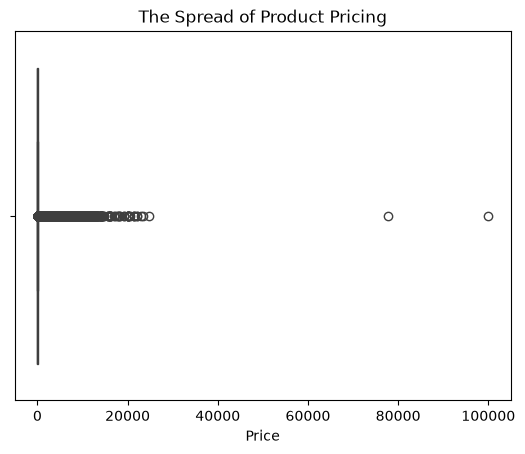

In [20]:
sns.boxplot(x=df_price["price"])
plt.title("The Spread of Product Pricing")
plt.xlabel("Price")
plt.show()

**Product Ratings**

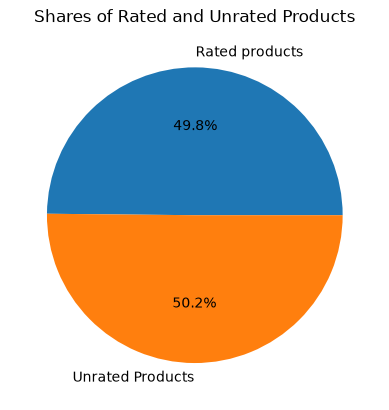

In [21]:
rated = (df["stars"] > 0).sum()
unrated = (df["stars"] == 0).sum()
plt.pie([rated,unrated],labels=["Rated products", "Unrated Products"],autopct="%1.1f%%") 
plt.title("Shares of Rated and Unrated Products")
plt.show()

In [25]:
stars = pd.to_numeric(df["stars"], errors="coerce")
df_rated = stars[stars > 0]
ranking = pd.DataFrame({
    "Min": [df_rated.min()],
    "Max": [df_rated.max()],
    "Mean": [df_rated.mean()],
    "Median": [df_rated.median()],
    "Mode": [df_rated.mode()[0]],
    "Variance": [df_rated.var()],
    "STD": [df_rated.std()],
    "Range": [df_rated.max() - df_rated.min()],
    "Interquartile range (IQR)": [df_rated.quantile(0.75) - df_rated.quantile(0.25)],
    "Skewness": [df_rated.skew()],
    "Kurtosis": [df_rated.kurt()]
})
ranking

,Min,Max,Mean,Median,Mode,Variance,STD,Range,Interquartile range (IQR),Skewness,Kurtosis
0,1.00,5.00,4.32,4.40,4.50,0.31,0.56,4.00,0.50,-2.38,9.78


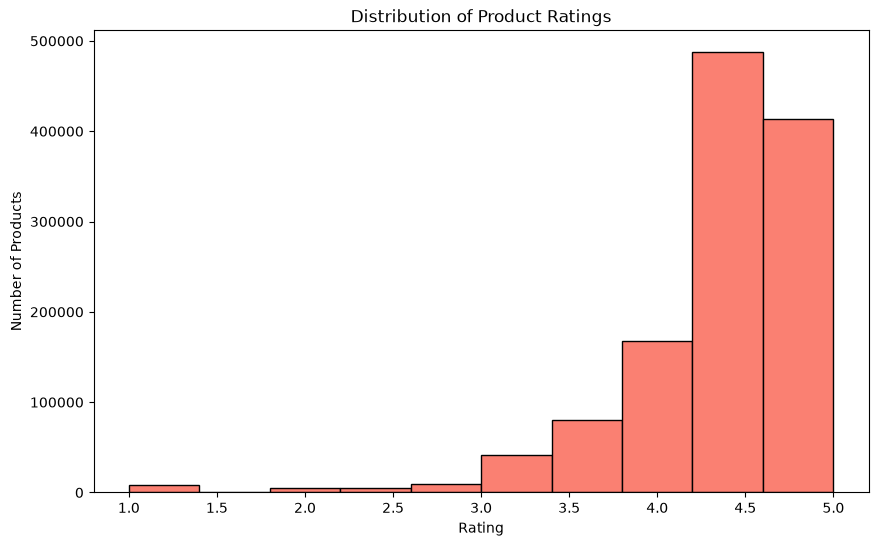

In [28]:
plt.figure(figsize=(10, 6))
plt.hist(df_rated,edgecolor="black",color="salmon")
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Products")
plt.show()

**Product categories:** Sports & Outdoors is by far the most frequently listed category, representing about 34% of all listings. The remaining categories are much smaller individually, indicating a highly uneven distribution across categories.

**Product prices:** After excluding zero prices, the mean price is £89.24, while the median is £19.09 and the mode is £9.99. This large difference indicates a strongly right-skewed distribution. Most products fall within the £10–£31.62 price range, while a small number of very expensive products extend up to £100,000, producing a large standard deviation and high-price outliers.

**Product ratings:** Considering only rated products, the mean rating is 4.32, the median 4.40, and the mode 4.50, showing that ratings are generally high. The standard deviation is only 0.56 and the IQR is 0.50, indicating relatively low variation. The distribution is strongly negatively skewed (-2.38), meaning ratings are concentrated toward the upper end of the scale, and the high kurtosis (9.78) indicates that the distribution differs substantially from a normal distribution.

**Best-seller trends**

In [31]:
best_seller_table = pd.crosstab(df["category"],df["isBestSeller"])
best_seller_table

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [33]:
best_seller_prop = pd.crosstab(df["category"],df["isBestSeller"],normalize="index")
best_seller_prop

isBestSeller,False,True
category,,
3D Printers,1.00,0.00
3D Printing & Scanning,1.00,0.00
Abrasive & Finishing Products,0.98,0.02
Action Cameras,1.00,0.00
Adapters,0.99,0.01
...,...,...
Wind Instruments,0.97,0.03
Window Treatments,0.98,0.02
Women,0.99,0.01


In [34]:
best_seller_prop[True].sort_values(ascending=False).head(10)

category
Grocery                          0.06
Smart Home Security & Lighting   0.06
Health & Personal Care           0.06
Mobile Phone Accessories         0.04
Power & Hand Tools               0.04
Billiard, Snooker & Pool         0.03
Pet Supplies                     0.03
Home Brewing & Wine Making       0.03
Mirrors                          0.03
Wind Instruments                 0.03
Name: True, dtype: float64

In [ ]:
chi2, p, dof, expected = chi2_contingency(best_seller_table)
print("Chi-square:", chi2)
print("p-value:", p)

Chi-square: 36540.20270061387
p-value: 0.0


In [ ]:
n = best_seller_table.sum().sum()
r, c = best_seller_table.shape
cramers_v = np.sqrt(chi2 / (n * min(r - 1, c - 1)))
# close to 0 → weak association
# close to 1 → strong association
cramers_v

np.float64(0.1222829439760564)

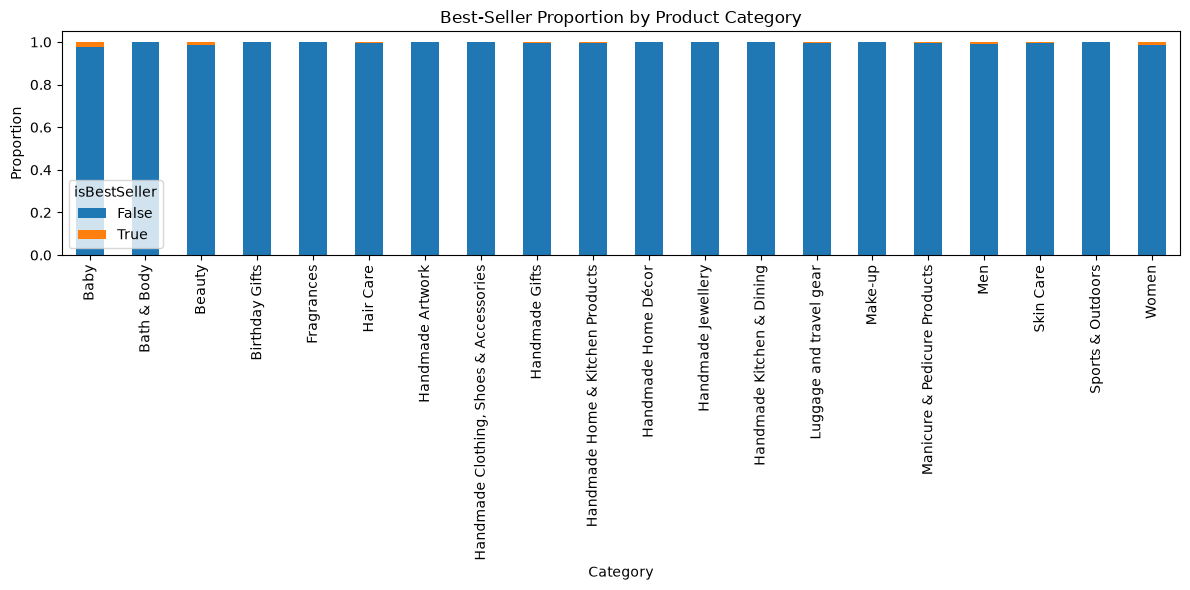

In [43]:
top20 = df["category"].value_counts().head(20).index
plot_data = pd.crosstab(df[df["category"].isin(top20)]["category"],df[df["category"].isin(top20)]["isBestSeller"],normalize="index")
plot_data.plot(kind="bar",stacked=True,figsize=(12, 6))
plt.title("Best-Seller Proportion by Product Category")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Best-Seller Analysis**

The highest proportion of best-sellers appears in Grocery, Smart Home Security & Lighting, and Health & Personal Care, at approximately 6% each.

The Chi-square test produced a very large statistic (36,540.20) and a p-value below 0.001, indicating that best-seller status and product category are not independent.

However, Cramér's V is only 0.122, showing that the association between category and best-seller status is relatively weak. Therefore, category is related to best-seller status, but the strength of this relationship is small.

**Product Prices and Ratings Across Categories**

In [54]:
df_price = df[df["price"] > 0]

Q1 = df_price["price"].quantile(0.25)
Q3 = df_price["price"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df_no_outliers = df_price[(df_price["price"] >= lower) & (df_price["price"] <= upper)]

print("Lower limit:", lower)
print("Upper limit:", upper)
print("Rows removed:", len(df_price) - len(df_no_outliers))

Lower limit: -44.01
Upper limit: 99.99000000000001
Rows removed: 327688


In [56]:
top20 = df_no_outliers["category"].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers["category"].isin(top20)]

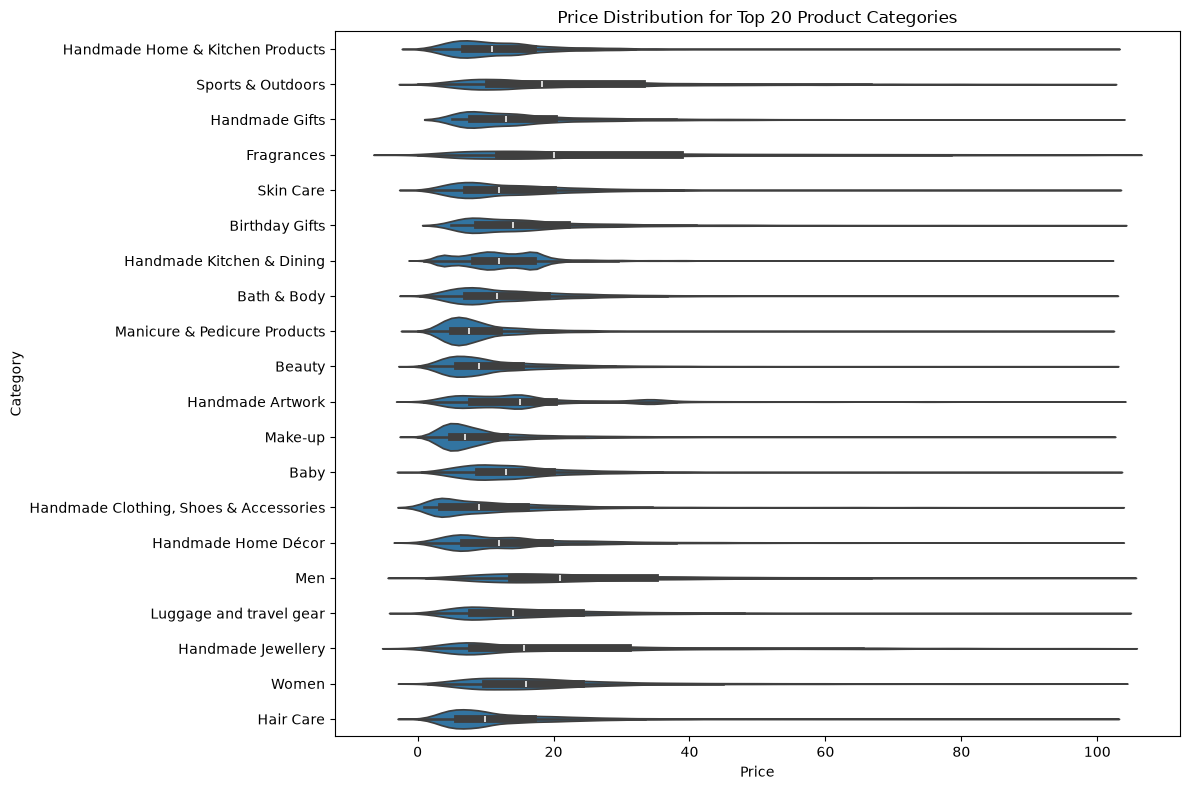

In [58]:
plt.figure(figsize=(12, 8))

sns.violinplot(data=df_top20,y="category",x="price")

plt.title("Price Distribution for Top 20 Product Categories")
plt.xlabel("Price")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [59]:
median_price = (df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False))
median_price.head(10)

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
Made in Italy Handmade   64.00
Digital Frames           63.90
Streaming Clients        62.68
Golf Shoes               62.39
Ski Helmets              61.33
Name: price, dtype: float64

In [65]:
top10 = df_no_outliers["category"].value_counts().head(10).index
top10

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='str', name='category')

In [66]:
avg_price_top10 = (df_no_outliers[df_no_outliers["category"].isin(top10)].groupby("category")["price"].mean().sort_values())
avg_price_top10

category
Manicure & Pedicure Products             10.23
Make-up                                  10.61
Beauty                                   12.52
Handmade Clothing, Shoes & Accessories   12.96
Hair Care                                13.46
Bath & Body                              14.68
Skin Care                                15.65
Handmade Gifts                           17.40
Birthday Gifts                           18.60
Sports & Outdoors                        25.17
Name: price, dtype: float64

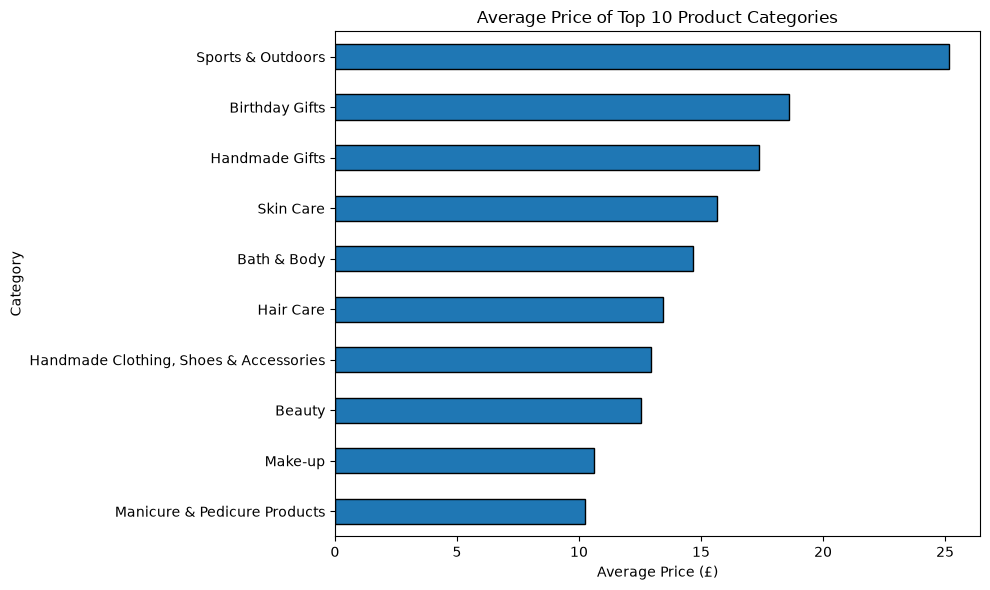

In [67]:
avg_price_top10.plot(kind="barh",figsize=(10, 6),edgecolor="black")
plt.title("Average Price of Top 10 Product Categories")
plt.xlabel("Average Price (£)")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [68]:
average_price = (df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False))
average_price.head(10)

category
Motherboards        68.77
Boxing Shoes        67.42
Desktop PCs         66.92
Tablets             66.55
Graphics Cards      65.10
Digital Frames      60.75
Streaming Clients   60.24
Hockey Shoes        60.09
Computer Cases      58.34
Skiing Poles        57.87
Name: price, dtype: float64

In [69]:
df_rated = df_no_outliers[df_no_outliers["stars"] > 0]

In [71]:
top10_rated = df_rated["category"].value_counts().head(10).index
df_rating_top10 = df_rated[df_rated["category"].isin(top10_rated)]

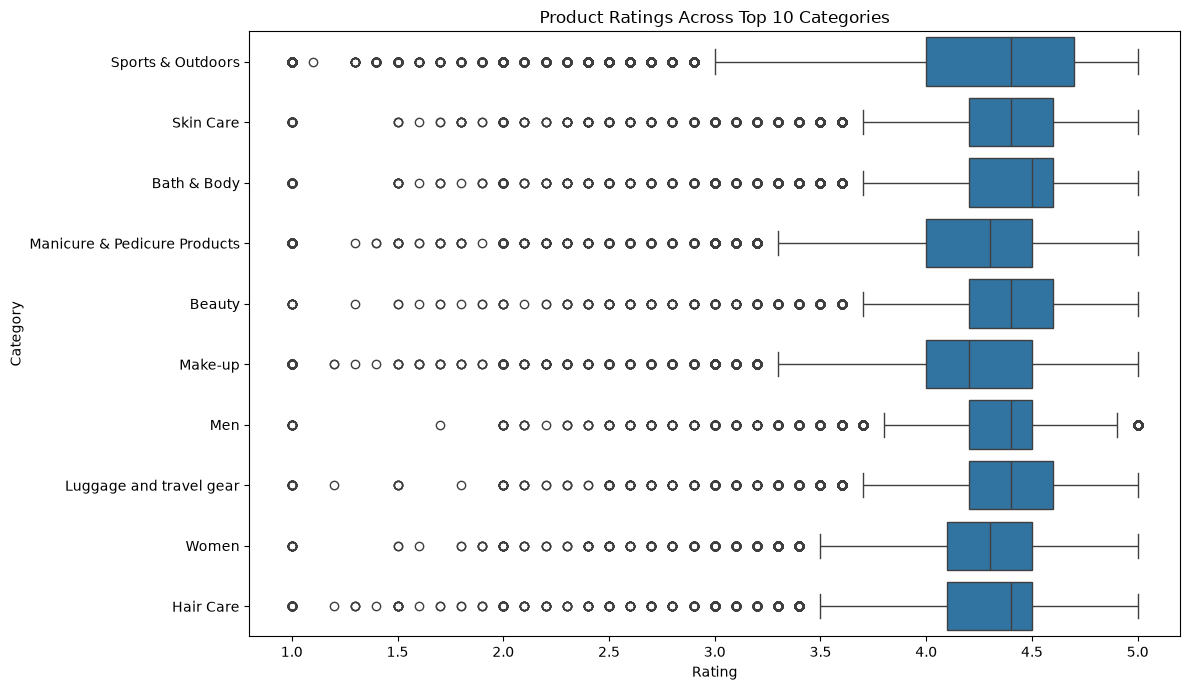

In [ ]:
plt.figure(figsize=(12,7))

sns.boxplot(data=df_rating_top10,y="category",x="stars")

plt.title("Product Ratings Across Top 10 Categories")
plt.xlabel("Rating")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [74]:
median_rating = (df_rated.groupby("category")["stars"].median().sort_values(ascending=False))
median_rating.head(10)

category
Handmade Artwork                         5.00
Made in Italy Handmade                   5.00
Handmade Baby Products                   5.00
Handmade Clothing, Shoes & Accessories   4.90
Handmade Kitchen & Dining                4.90
Birthday Gifts                           4.80
Handmade Home Décor                      4.80
Handmade Gifts                           4.80
Handmade Home & Kitchen Products         4.70
Computer Memory                          4.70
Name: stars, dtype: float64

In [75]:
highest_median = median_rating.max()

median_rating[median_rating == highest_median]

category
Handmade Artwork         5.00
Made in Italy Handmade   5.00
Handmade Baby Products   5.00
Name: stars, dtype: float64

**Relationship Between Price and Ratings**

In [77]:
df_corr = df_no_outliers[df_no_outliers["stars"] > 0]
correlation = df_corr["price"].corr(df_corr["stars"])
correlation

np.float64(0.006752653544295446)

In [78]:
from scipy.stats import pearsonr
r, p = pearsonr(df_corr["price"],df_corr["stars"])
print("Correlation:", r)
print("p-value:", p)

Correlation: 0.006752653544295431
p-value: 1.0163416388331078e-12


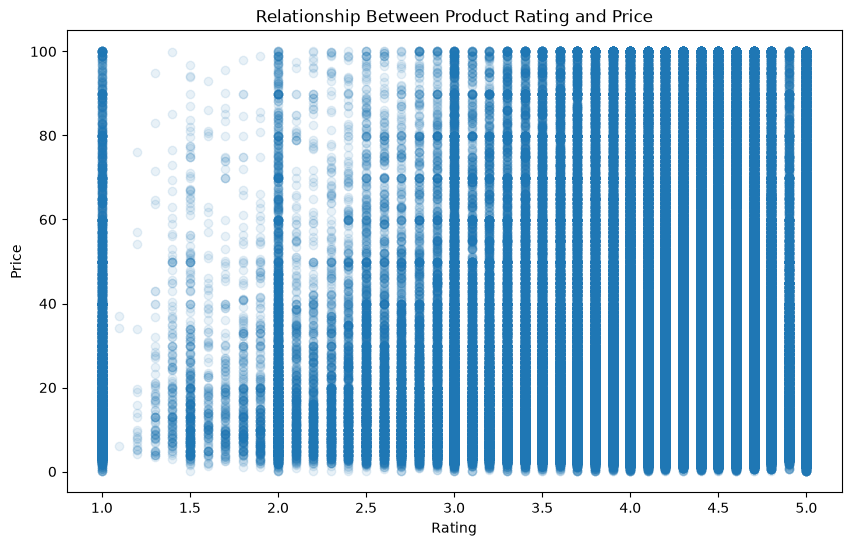

In [79]:
plt.figure(figsize=(10, 6))

plt.scatter(df_corr["stars"],df_corr["price"],alpha=0.1)

plt.title("Relationship Between Product Rating and Price")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()

In [86]:
numeric_df = df_corr.select_dtypes(include="number")
correlation_matrix = numeric_df.corr()
correlation_matrix

,uid,stars,reviews,price,boughtInLastMonth
uid,1.00,-0.01,0.02,-0.03,0.02
stars,-0.01,1.00,0.03,0.01,0.04
reviews,0.02,0.03,1.00,-0.00,0.10
price,-0.03,0.01,-0.00,1.00,-0.07
boughtInLastMonth,0.02,0.04,0.10,-0.07,1.00


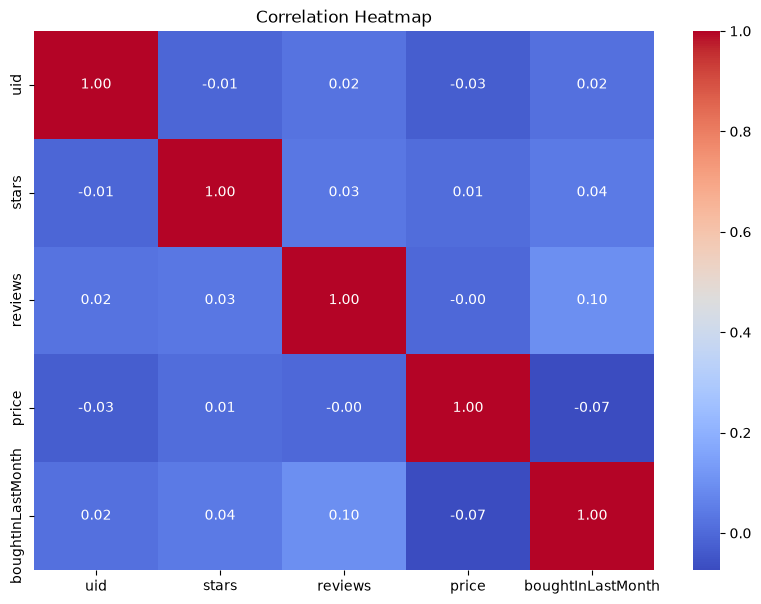

In [87]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix,annot=True,fmt=".2f",cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

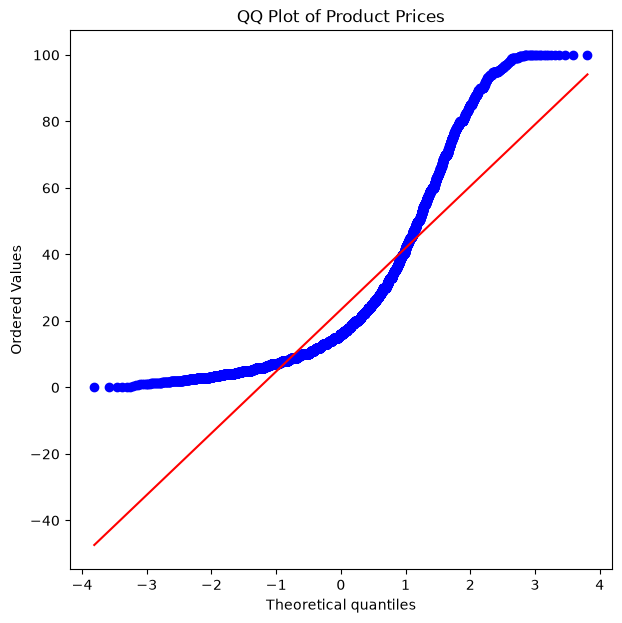

In [85]:
price_sample = df_no_outliers["price"].sample(10000,random_state=42)
price_sample = df_no_outliers["price"].sample(10000,random_state=42)
plt.figure(figsize=(7, 7))

stats.probplot(price_sample,dist="norm",plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()

### Summary

After removing price outliers using the IQR method, 327,688 products were excluded and the remaining prices were limited to approximately £100 or less.

Across all categories, Desktop PCs had the highest median price at £74.00, while Motherboards had the highest average price at £68.77. Among the 10 most common categories, Sports & Outdoors had the highest average price at £25.17.

For ratings, Handmade Artwork, Made in Italy Handmade, and Handmade Baby Products had the highest median rating of 5.0.

Pearson correlation between product price and rating was 0.0068, with a very small p-value. Although statistically significant, the linear relationship between price and rating is negligible.

The scatter plot also shows no clear relationship between rating and price. The QQ plot shows strong deviation from the reference line, indicating that product prices do not follow a normal distribution even after removing outliers.